# 선석점유율

선석 점유율 = Σ 작업시간 ÷ (선석 수 × 기간 시간) × 100

In [ ]:
# 작업시간 = 재항시간-추정대기시간
# 추정대기시간 = max(0,이전 배 출항 - 현재 배 입항)



In [11]:
import pandas as pd

df = pd.read_csv(
    "../data/record_except_168.csv",
    encoding="utf-8-sig"
)

print(df.head())

    호출부호              선명    입항횟수      총톤수                 입항일시  \
0  3FRF8     SONG YUN HE  2022.0   16,737  2022-01-01 00:48:00   
1  VRNA9  SEASPAN THAMES  2022.0  112,967  2022-01-01 02:00:00   
2  VRRP8  CMA CGM MUMBAI  2022.0  112,967  2022-01-01 03:00:00   
3  D5TL4       MSC JEWEL  2022.0  140,976  2022-01-01 03:22:00   
4  A8YT7        MALIAKOS  2022.0   41,391  2022-01-01 03:35:00   

                  출항일시           CIQ수속일자              수리일시       MRN 번호  \
0  2022-01-03 01:52:00   2022-01-03 1:52  2022-01-03 15:58  22COHES152E   
1  2022-01-02 17:43:00  2022-01-02 17:43  2022-01-03 11:18  22HLCU4202E   
2  2022-01-02 04:06:00   2022-01-02 4:00  2022-01-03 11:22  22CMAL0030E   
3  2022-01-03 05:00:00   2022-01-03 5:00  2022-01-03 11:19  22MSCU0004E   
4  2022-01-01 16:45:00  2022-01-01 16:00  2022-01-03 11:07  22SMLME016E   

         계선장소         차항지       전출항지       재항시간  
0  신항 5부두 3선석     QINGDAO         광양  49.066667  
1  신항 3부두 4선석   VANCOUVER   SHANGHAI  39.716667  
2 

# 부두별 총 재항시간

In [39]:
import pandas as pd

# CSV 파일을 파이썬 코드와 같은 폴더에 두세요.
df = pd.read_csv("../data/record.csv", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

for col in ["입항일시", "출항일시"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

df["부두"] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두", expand=False
)
df["재항시간"] = (
    df["출항일시"] - df["입항일시"]
).dt.total_seconds() / 3600

# 날짜 누락·변환 실패 및 음수 시간 제외
result = (
    df.loc[df["재항시간"].ge(0)]
    .groupby("부두")["재항시간"].sum()
    .reindex(list("12345"), fill_value=0)
    .rename_axis("부두")
    .rename("총 재항시간(시간)")
)
result.index = result.index + "부두"

print(result.round(2).to_string())

부두
1부두    88682.35
2부두   158771.60
3부두    88756.00
4부두    80988.10
5부두   100373.73


# 총 추정대기 시간

In [41]:


# 부두·선석 추출: 예) 신항 1부두 2선석
df[["부두", "선석"]] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두\s*(\d+)\s*선석"
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")
df = df.dropna(subset=["부두", "선석", "입항", "출항"])

# 같은 선석에서 입항 순서상 직전 선박의 출항 시각
df = df.sort_values(["부두", "선석", "입항"], kind="stable")
df["앞배_출항"] = df.groupby(["부두", "선석"])["출항"].shift()

# 추정대기시간: 시간 단위, 음수 및 첫 선박은 0
df["추정대기"] = (
    (df["앞배_출항"] - df["입항"]).dt.total_seconds() / 3600
).clip(lower=0).fillna(0)

result = (
    df.groupby("부두")["추정대기"].sum()
    .reindex(list("12345"), fill_value=0)
    .rename("총 추정대기시간(시간)")
)
result.index = result.index + "부두"

print(result.round(2).to_string())

부두
1부두    5889.05
2부두   14732.18
3부두    8779.27
4부두    6866.35
5부두   14665.58


In [43]:
result = (
    df.groupby("부두")[["재항시간", "추정대기"]]
    .sum()
    .reindex(list("12345"), fill_value=0)
)

result.columns = ["총 재항시간", "총 추정대기시간"]
result["작업시간"] = result["총 재항시간"] - result["총 추정대기시간"]
result.index = result.index + "부두"

print(result.round(2).to_string())

       총 재항시간  총 추정대기시간      작업시간
부두                               
1부두  88682.35   5889.05  82793.30
2부두 158771.60  14732.18 144039.42
3부두  88756.00   8779.27  79976.73
4부두  80988.10   6866.35  74121.75
5부두 100373.73  14665.58  85708.15


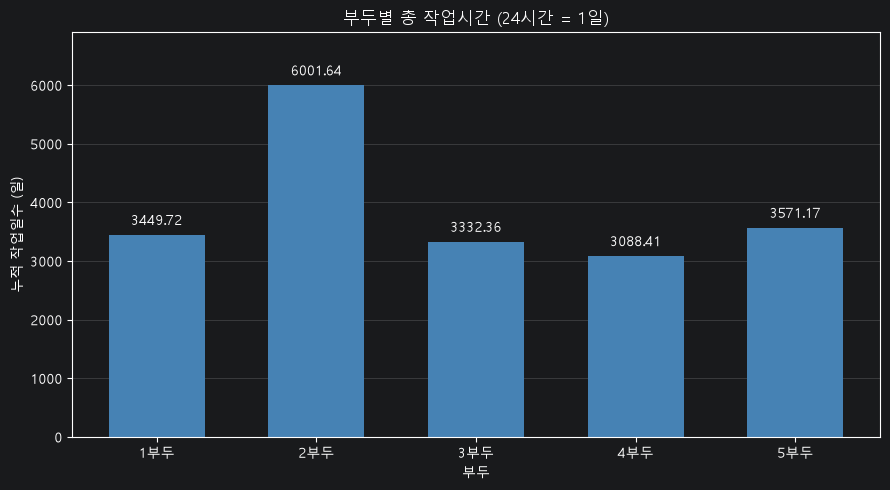

In [51]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 시간 → 일 변환
작업일수 = result["작업시간"] / 24

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(작업일수.index, 작업일수, color="steelblue", width=0.6)

ax.bar_label(bars, fmt="%.2f", padding=5)
ax.set_title("부두별 총 작업시간 (24시간 = 1일)")
ax.set_xlabel("부두")
ax.set_ylabel("누적 작업일수 (일)")
ax.set_ylim(0, 작업일수.max() * 1.15)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [52]:
import pandas as pd

# 앞서 제공한 이미지 기준 선석 수
선석수 = {1: 3, 2: 6, 3: 4, 4: 4, 5: 4}

선석수표 = pd.DataFrame({
    "부두": list(선석수.keys()),
    "선석수": list(선석수.values())
})

print(선석수표.to_string(index=False))

 부두  선석수
  1    3
  2    6
  3    4
  4    4
  5    4


In [46]:
import pandas as pd

# 1) 계산 기간: 2025년 전체
year = 2025
start = pd.Timestamp(year=year, month=1, day=1)
end = pd.Timestamp(year=year + 1, month=1, day=1)
period_hours = (end - start).total_seconds() / 3600  # 8,760시간

# 실제 시설 선석 수: 이미지 기준
berth_counts = pd.Series(
    {"1": 3, "2": 6, "3": 4, "4": 4, "5": 4},
    name="선석 수"
)

# 2) 전체 기록에서 같은 선석 직전 선박 확인
data = df.dropna(subset=["부두", "선석", "입항", "출항"]).copy()
data = data.loc[data["출항"] >= data["입항"]]
data = data.sort_values(["부두", "선석", "입항"], kind="stable")

data["앞배_출항"] = data.groupby(["부두", "선석"])["출항"].shift()

# 3) 추정대기가 끝난 시각부터 출항까지를 작업시간으로 계산
data["작업시작"] = data[["입항", "앞배_출항"]].max(axis=1)

# 연도를 넘는 기록은 2025년에 해당하는 시간만 반영
data["기간내_작업시간"] = (
    (
        data["출항"].clip(upper=end)
        - data["작업시작"].clip(lower=start)
    ).dt.total_seconds() / 3600
).clip(lower=0)

# 4) 부두별 합계 및 선석 점유율
occupancy = berth_counts.to_frame()
occupancy["기간 시간"] = period_hours
occupancy["총 작업시간"] = (
    data.groupby("부두")["기간내_작업시간"].sum()
    .reindex(occupancy.index, fill_value=0)
)
occupancy["가용 선석시간"] = (
    occupancy["선석 수"] * occupancy["기간 시간"]
)
occupancy["선석 점유율(%)"] = (
    occupancy["총 작업시간"] / occupancy["가용 선석시간"] * 100
)

occupancy.index = occupancy.index + "부두"
occupancy.index.name = "부두"

print(f"{year}년 기준 / 기간: {period_hours:,.0f}시간")
print(occupancy.round(2).to_string())

2025년 기준 / 기간: 8,760시간
     선석 수   기간 시간   총 작업시간  가용 선석시간  선석 점유율(%)
부두                                            
1부두     3 8760.00 22073.60 26280.00      83.99
2부두     6 8760.00 36207.40 52560.00      68.89
3부두     4 8760.00 21471.10 35040.00      61.28
4부두     4 8760.00 19647.53 35040.00      56.07
5부두     4 8760.00 21081.28 35040.00      60.16


       1부두   2부두   3부두   4부두   5부두
연도                                
2022 77.98 68.18 58.03 51.96 72.49
2023 77.74 76.05 57.28 54.37 64.37
2024 82.94 71.70 61.78 55.78 62.79
2025 83.99 68.89 61.28 56.07 60.16


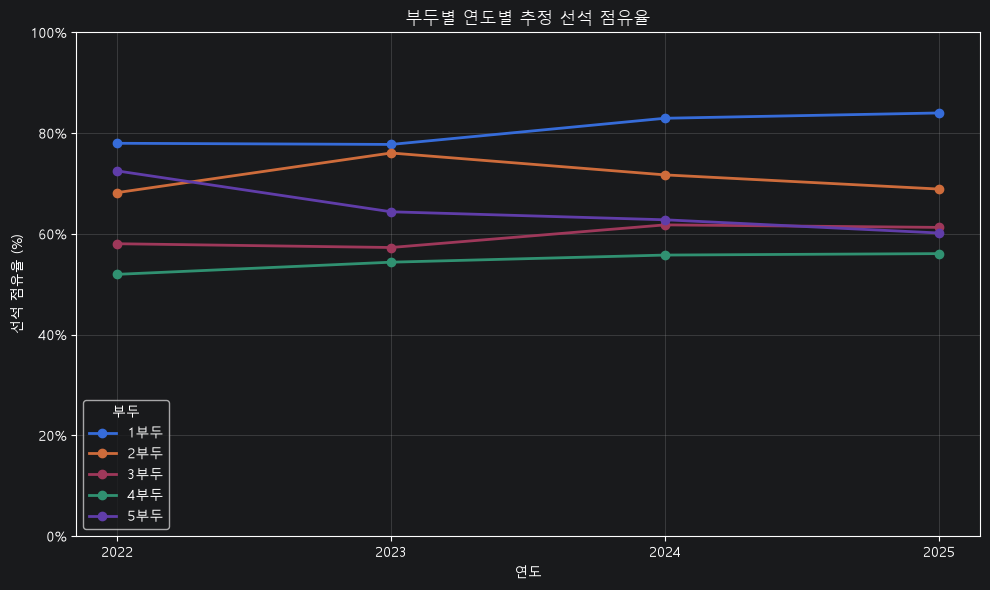

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 이미지 기준 선석 수: 모든 연도에 동일하게 적용
berth_counts = pd.Series({"1": 3, "2": 6, "3": 4, "4": 4, "5": 4})

data = df.copy()
for col in ["입항", "출항"]:
    data[col] = pd.to_datetime(data[col], errors="coerce")

data = data.dropna(subset=["부두", "선석", "입항", "출항"])
data = data.loc[data["출항"] >= data["입항"]].copy()
data["부두"] = data["부두"].astype(str)

# 같은 선석의 직전 선박을 기준으로 작업시작 계산
data = data.sort_values(["부두", "선석", "입항"], kind="stable")
data["앞배_출항"] = data.groupby(["부두", "선석"])["출항"].shift()
data["작업시작"] = data[["입항", "앞배_출항"]].max(axis=1)

# 2022~2025년 연도별 점유율
annual = {}
for year in range(2022, 2026):
    start = pd.Timestamp(year=year, month=1, day=1)
    end = pd.Timestamp(year=year + 1, month=1, day=1)
    period_hours = (end - start).total_seconds() / 3600

    work_hours = (
        (
            data["출항"].clip(upper=end)
            - data["작업시작"].clip(lower=start)
        ).dt.total_seconds() / 3600
    ).clip(lower=0)

    totals = work_hours.groupby(data["부두"]).sum()
    annual[year] = (
        totals.reindex(berth_counts.index, fill_value=0)
        / (berth_counts * period_hours) * 100
    )

annual = pd.DataFrame(annual).T
annual.columns = annual.columns + "부두"
annual.index.name = "연도"

print(annual.round(2).to_string())

# 라인그래프
fig, ax = plt.subplots(figsize=(10, 6))

for terminal in annual.columns:
    ax.plot(
        annual.index, annual[terminal],
        marker="o", linewidth=2, label=terminal
    )

ax.set_title("부두별 연도별 추정 선석 점유율")
ax.set_xlabel("연도")
ax.set_ylabel("선석 점유율 (%)")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(0, max(100, annual.max().max() * 1.15))
ax.grid(alpha=0.3)
ax.legend(title="부두")

plt.tight_layout()
plt.show()